In [4]:

import numpy as np
import matplotlib.pyplot as plt

import jax
jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp
import diffrax as dfx

import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

print("JAX version:", jax.__version__)
print("Device:", jax.devices())


JAX version: 0.11.2
Device: [CpuDevice(id=0)]


In [5]:

def rhs(t, x, theta):
    a, b = theta

    dx1 = -a * x[0]
    dx2 = a * x[0] - b * x[1]

    return jnp.stack([dx1, dx2])


def solve_ode(theta, x0, ts):
    solution = dfx.diffeqsolve(
        terms=dfx.ODETerm(rhs),
        solver=dfx.Tsit5(),
        t0=0.0,
        t1=ts[-1],
        dt0=0.05,
        y0=x0,
        args=theta,
        saveat=dfx.SaveAt(ts=ts),
        stepsize_controller=dfx.PIDController(
            rtol=1e-6,
            atol=1e-8,
        ),
        max_steps=8192,
    )

    return solution.ys


In [6]:

# Reproduzierbarkeit
key = jax.random.PRNGKey(42)
key_times, key_noise, key_mcmc = jax.random.split(key, 3)

# Wahre Parameter
theta_true = jnp.array([0.7, 0.25])
x0_true = jnp.array([2.0, 0.4])

# Tatsächliches Beobachtungsrauschen
sigma_true = jnp.array([0.06, 0.08])

# Zufällige Beobachtungszeitpunkte
T = 12.0
n_obs_random = 60

ts_random = jax.random.uniform(
    key_times,
    shape=(n_obs_random,),
    minval=0.0,
    maxval=T,
)

ts = jnp.sort(
    jnp.concatenate([
        jnp.array([0.0, T]),
        ts_random,
    ])
)

# Exakte ODE-Trajektorie (numerisch berechnet)
ys_clean = solve_ode(theta_true, x0_true, ts)

# Beobachtungsrauschen hinzufügen
noise = (
    jax.random.normal(key_noise, ys_clean.shape)
    * sigma_true
)

ys = ys_clean + noise

print("ts:", ts.shape)
print("ys:", ys.shape)


ts: (62,)
ys: (62, 2)


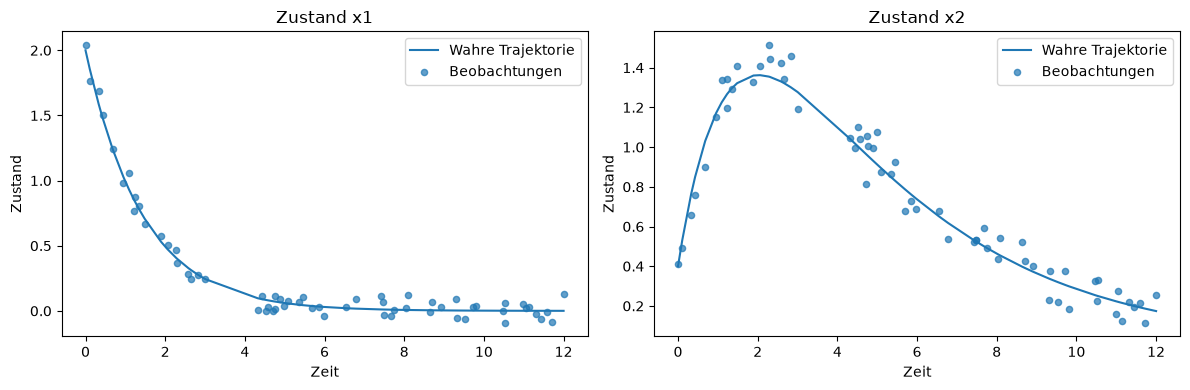

In [7]:

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4), sharex=True
)

for i, ax in enumerate(axes):
    ax.plot(
        np.asarray(ts),
        np.asarray(ys_clean[:, i]),
        label="Wahre Trajektorie"
    )

    ax.scatter(
        np.asarray(ts),
        np.asarray(ys[:, i]),
        s=20,
        alpha=0.7,
        label="Beobachtungen"
    )

    ax.set_title(f"Zustand x{i+1}")
    ax.set_xlabel("Zeit")
    ax.set_ylabel("Zustand")
    ax.legend()

plt.tight_layout()
plt.show()


In [9]:

def model(ts, ys=None):

    # Priors für die ODE-Parameter a und b
    theta = numpyro.sample(
        "theta",
        dist.LogNormal(
            jnp.log(jnp.array([0.5, 0.3])),
            jnp.array([0.7, 0.7])
        ).to_event(1)
    )

    # Priors für die Anfangsbedingungen
    x0 = numpyro.sample(
        "x0",
        dist.LogNormal(
            jnp.log(jnp.array([1.5, 0.4])),
            jnp.array([0.7, 0.7])
        ).to_event(1)
    )

    # Beobachtungsrauschen pro Zustandsvariable
    sigma = numpyro.sample(
        "sigma",
        dist.HalfNormal(0.2).expand([2]).to_event(1)
    )

    # ODE für die aktuellen Parameter lösen
    predictions = solve_ode(theta, x0, ts)

    # Likelihood aller Beobachtungen
    numpyro.sample(
        "obs",
        dist.Normal(
            loc=predictions,
            scale=sigma
        ).to_event(2),
        obs=ys
    )


In [10]:

nuts_kernel = NUTS(
    model,
    target_accept_prob=0.85
)

mcmc = MCMC(
    nuts_kernel,
    num_warmup=500,
    num_samples=800,
    num_chains=2,
    chain_method="sequential"
)

mcmc.run(
    key_mcmc,
    ts=ts,
    ys=ys,
    extra_fields=("diverging",)
)

mcmc.print_summary()

posterior = mcmc.get_samples()


sample: 100%|██████████| 1300/1300 [00:04<00:00, 289.74it/s, 15 steps of size 4.01e-01. acc. prob=0.93]



                mean       std    median      5.0%     95.0%     n_eff     r_hat
  sigma[0]      0.06      0.01      0.06      0.05      0.07   1329.87      1.00
  sigma[1]      0.08      0.01      0.08      0.07      0.09   1520.55      1.00
  theta[0]      0.72      0.02      0.72      0.69      0.75    706.12      1.00
  theta[1]      0.24      0.00      0.24      0.24      0.25   1190.84      1.00
     x0[0]      2.05      0.03      2.05      1.99      2.10    753.54      1.00
     x0[1]      0.36      0.04      0.36      0.30      0.42    717.93      1.00

Number of divergences: 0


In [11]:

true_values = {
    "theta": np.asarray(theta_true),
    "x0": np.asarray(x0_true),
    "sigma": np.asarray(sigma_true),
}

parameter_names = {
    "theta": ["a", "b"],
    "x0": ["x0_1", "x0_2"],
    "sigma": ["sigma_1", "sigma_2"],
}

for group in ["theta", "x0", "sigma"]:
    samples = np.asarray(posterior[group])

    lower, median, upper = np.quantile(
        samples,
        [0.05, 0.5, 0.95],
        axis=0
    )

    for i, name in enumerate(parameter_names[group]):
        print(
            f"{name:10s} "
            f"true={true_values[group][i]:.3f}  "
            f"median={median[i]:.3f}  "
            f"90% CI=[{lower[i]:.3f}, {upper[i]:.3f}]"
        )


a          true=0.700  median=0.719  90% CI=[0.691, 0.749]
b          true=0.250  median=0.245  90% CI=[0.237, 0.253]
x0_1       true=2.000  median=2.047  90% CI=[1.995, 2.103]
x0_2       true=0.400  median=0.356  90% CI=[0.297, 0.414]
sigma_1    true=0.060  median=0.060  90% CI=[0.052, 0.070]
sigma_2    true=0.080  median=0.077  90% CI=[0.067, 0.089]


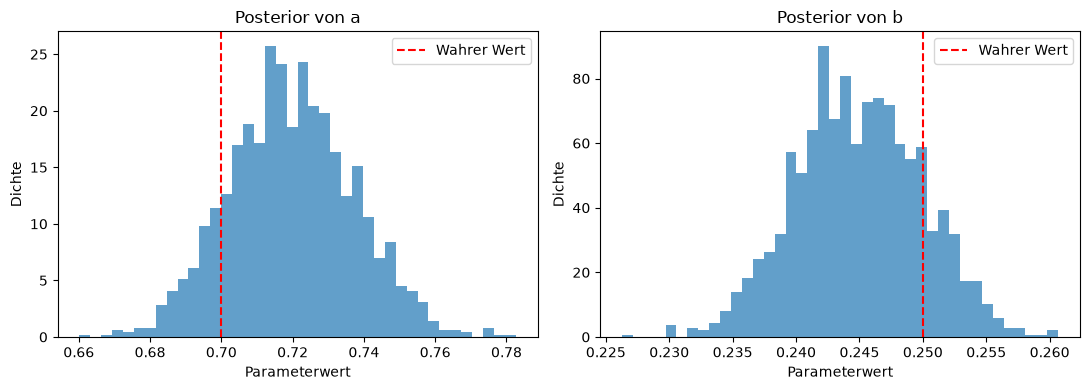

In [12]:

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

theta_samples = np.asarray(posterior["theta"])

for i, ax in enumerate(axes):
    ax.hist(
        theta_samples[:, i],
        bins=40,
        density=True,
        alpha=0.7
    )

    ax.axvline(
        float(theta_true[i]),
        color="red",
        linestyle="--",
        label="Wahrer Wert"
    )

    ax.set_title(f"Posterior von {['a', 'b'][i]}")
    ax.set_xlabel("Parameterwert")
    ax.set_ylabel("Dichte")
    ax.legend()

plt.tight_layout()
plt.show()


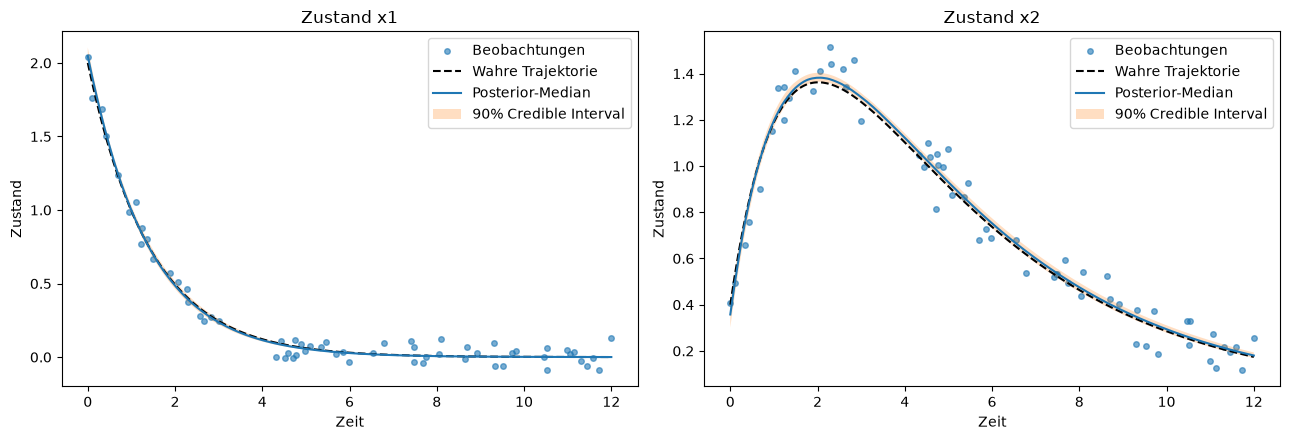

In [13]:

# Feineres Zeitgitter für die Visualisierung
t_grid = jnp.linspace(0.0, T, 250)

# 80 Samples aus dem Posterior auswählen
n_draws = 80
n_total = posterior["theta"].shape[0]

idx = jnp.linspace(
    0, n_total - 1, n_draws
).astype(int)

theta_draws = posterior["theta"][idx]
x0_draws = posterior["x0"][idx]

# ODE für alle Posterior-Samples lösen
trajectories = jax.vmap(
    solve_ode,
    in_axes=(0, 0, None)
)(
    theta_draws,
    x0_draws,
    t_grid
)

trajectories = np.asarray(trajectories)

# Posterior-Zusammenfassung
lower = np.quantile(trajectories, 0.05, axis=0)
median = np.quantile(trajectories, 0.50, axis=0)
upper = np.quantile(trajectories, 0.95, axis=0)

# Wahre Trajektorie
true_trajectory = np.asarray(
    solve_ode(theta_true, x0_true, t_grid)
)

# Plot
fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.5), sharex=True
)

for i, ax in enumerate(axes):

    ax.scatter(
        np.asarray(ts),
        np.asarray(ys[:, i]),
        s=16,
        alpha=0.6,
        label="Beobachtungen"
    )

    ax.plot(
        np.asarray(t_grid),
        true_trajectory[:, i],
        "k--",
        label="Wahre Trajektorie"
    )

    ax.plot(
        np.asarray(t_grid),
        median[:, i],
        label="Posterior-Median"
    )

    ax.fill_between(
        np.asarray(t_grid),
        lower[:, i],
        upper[:, i],
        alpha=0.25,
        label="90% Credible Interval"
    )

    ax.set_title(f"Zustand x{i+1}")
    ax.set_xlabel("Zeit")
    ax.set_ylabel("Zustand")
    ax.legend()

plt.tight_layout()
plt.show()


In [14]:

extra = mcmc.get_extra_fields()

n_divergences = int(
    np.asarray(extra["diverging"]).sum()
)

print("Anzahl Divergenzen:", n_divergences)


Anzahl Divergenzen: 0
